<center><h1>Свёртки

<center><h2>Сверточные слои

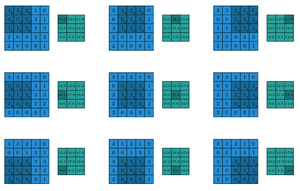

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader

In [2]:
train_data = datasets.MNIST(root='./SimpleNN', train=True, download=True, transform=transforms.ToTensor())
valid_data = datasets.MNIST(root='./SimpleNN', train=False, download=True, transform=transforms.ToTensor())

100%|██████████| 9.91M/9.91M [00:09<00:00, 1.03MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 191kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 873kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.91MB/s]


In [55]:
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=16, shuffle=False)

In [4]:
conv_layer = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3)

In [5]:
conv_layer

Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1))

In [6]:
dataiter = iter(valid_loader)
image, _ = next(dataiter)
image

tensor([[[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [7]:
image.shape

torch.Size([1, 1, 28, 28])

1 - размер пакета

1 - каналы

28, 28 - размеры

In [8]:
conv_output = conv_layer(image)
conv_output

tensor([[[[0.2935, 0.2935, 0.2935,  ..., 0.2935, 0.2935, 0.2935],
          [0.2935, 0.2935, 0.2935,  ..., 0.2935, 0.2935, 0.2935],
          [0.2935, 0.2935, 0.2935,  ..., 0.2935, 0.2935, 0.2935],
          ...,
          [0.2935, 0.2935, 0.2935,  ..., 0.2935, 0.2935, 0.2935],
          [0.2935, 0.2935, 0.2935,  ..., 0.2935, 0.2935, 0.2935],
          [0.2935, 0.2935, 0.2935,  ..., 0.2935, 0.2935, 0.2935]],

         [[0.0252, 0.0252, 0.0252,  ..., 0.0252, 0.0252, 0.0252],
          [0.0252, 0.0252, 0.0252,  ..., 0.0252, 0.0252, 0.0252],
          [0.0252, 0.0252, 0.0252,  ..., 0.0252, 0.0252, 0.0252],
          ...,
          [0.0252, 0.0252, 0.0252,  ..., 0.0252, 0.0252, 0.0252],
          [0.0252, 0.0252, 0.0252,  ..., 0.0252, 0.0252, 0.0252],
          [0.0252, 0.0252, 0.0252,  ..., 0.0252, 0.0252, 0.0252]],

         [[0.1418, 0.1418, 0.1418,  ..., 0.1418, 0.1418, 0.1418],
          [0.1418, 0.1418, 0.1418,  ..., 0.1418, 0.1418, 0.1418],
          [0.1418, 0.1418, 0.1418,  ..., 0

In [10]:
conv_output.shape

torch.Size([1, 4, 26, 26])

<h3>Слой субдискритизации (pooling)

+Добавляет стабильности (так как сверточная сеть может неправильно воспринять данные, локально зациклиться)

In [11]:
pool_layer = nn.MaxPool2d(kernel_size=2)
# Тут max значит берем макисмум из области

In [13]:
pool_output = pool_layer(conv_output)
pool_output

tensor([[[[ 2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,
            2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,
            2.9354e-01,  2.9354e-01,  2.9354e-01],
          [ 2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,
            2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,
            2.9354e-01,  2.9354e-01,  2.9354e-01],
          [ 2.9354e-01,  2.9354e-01,  5.6079e-01,  5.5899e-01,  3.8629e-01,
            2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,  2.9354e-01,
            2.9354e-01,  2.9354e-01,  2.9354e-01],
          [ 2.9354e-01,  2.9354e-01,  5.7399e-01,  5.3847e-01,  6.4062e-01,
            5.6451e-01,  5.5556e-01,  5.5556e-01,  5.5556e-01,  5.2384e-01,
            3.2521e-01,  2.9354e-01,  2.9354e-01],
          [ 2.9354e-01,  2.9354e-01,  3.5502e-01,  4.0285e-01,  3.8567e-01,
            3.7070e-01,  4.5408e-01,  4.0336e-01,  7.0137e-01,  6.4857e-01,
            4.2340e-01,  2.9354e-01,

In [14]:
pool_output.shape

torch.Size([1, 4, 13, 13])

А было 26x26

<h3>Stride

<text>Определяет количество пропущенных ячеек. Другими словами, определяет шаг ядра

In [15]:
stride_conv = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, stride=2)

In [17]:
stride_output = stride_conv(image)
stride_output

tensor([[[[ 0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,
            0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508],
          [ 0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,
            0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508],
          [ 0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,
            0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508],
          [ 0.0508,  0.0508,  0.0753, -0.3502, -0.3331, -0.1620, -0.0697,
           -0.0697, -0.0697, -0.0724,  0.0042,  0.0508,  0.0508],
          [ 0.0508,  0.0508,  0.2212, -0.1650, -0.1943, -0.4020, -0.3658,
           -0.4354, -0.4307, -0.5329, -0.4536,  0.0508,  0.0508],
          [ 0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0988,  0.0341,
            0.0273,  0.0053, -0.3067, -0.2971,  0.0508,  0.0508],
          [ 0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,  0.0508,
            0.0564, -0.0634, -0.5711, -0.0431,  0.0508,  0.0508],
          [ 0.0508, 

In [18]:
stride_output.shape

torch.Size([1, 4, 13, 13])

<h3>Padding

<text>Позволяет сохранять (даже увеличивать) исходный размер изображения после свертки при помощи дополнения изображения краевыми значениями (часто 0)

Желательно предварительно изучить данные иначе подбираем параметры эвристически

In [25]:
padding_layer = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, padding=1)

In [27]:
padding_output = padding_layer(image)
padding_output

tensor([[[[ 0.0763,  0.0763,  0.0763,  ...,  0.0763,  0.0763,  0.0763],
          [ 0.0763,  0.0763,  0.0763,  ...,  0.0763,  0.0763,  0.0763],
          [ 0.0763,  0.0763,  0.0763,  ...,  0.0763,  0.0763,  0.0763],
          ...,
          [ 0.0763,  0.0763,  0.0763,  ...,  0.0763,  0.0763,  0.0763],
          [ 0.0763,  0.0763,  0.0763,  ...,  0.0763,  0.0763,  0.0763],
          [ 0.0763,  0.0763,  0.0763,  ...,  0.0763,  0.0763,  0.0763]],

         [[-0.0402, -0.0402, -0.0402,  ..., -0.0402, -0.0402, -0.0402],
          [-0.0402, -0.0402, -0.0402,  ..., -0.0402, -0.0402, -0.0402],
          [-0.0402, -0.0402, -0.0402,  ..., -0.0402, -0.0402, -0.0402],
          ...,
          [-0.0402, -0.0402, -0.0402,  ..., -0.0402, -0.0402, -0.0402],
          [-0.0402, -0.0402, -0.0402,  ..., -0.0402, -0.0402, -0.0402],
          [-0.0402, -0.0402, -0.0402,  ..., -0.0402, -0.0402, -0.0402]],

         [[ 0.1506,  0.1506,  0.1506,  ...,  0.1506,  0.1506,  0.1506],
          [ 0.1506,  0.1506,  

In [28]:
padding_output.shape

torch.Size([1, 4, 28, 28])

Размер сохранился

<h3>Dilation

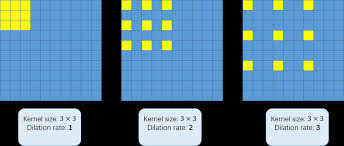

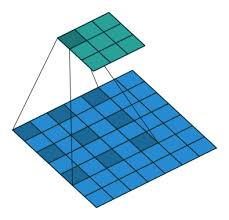

In [29]:
dilated_layer = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, dilation=2)

In [30]:
dilated_output = dilated_layer(image)
dilated_output

tensor([[[[ 0.1407,  0.1407,  0.1407,  ...,  0.1407,  0.1407,  0.1407],
          [ 0.1407,  0.1407,  0.1407,  ...,  0.1407,  0.1407,  0.1407],
          [ 0.1407,  0.1407,  0.1407,  ...,  0.1407,  0.1407,  0.1407],
          ...,
          [ 0.1407,  0.1407,  0.1407,  ...,  0.1407,  0.1407,  0.1407],
          [ 0.1407,  0.1407,  0.1407,  ...,  0.1407,  0.1407,  0.1407],
          [ 0.1407,  0.1407,  0.1407,  ...,  0.1407,  0.1407,  0.1407]],

         [[ 0.3183,  0.3183,  0.3183,  ...,  0.3183,  0.3183,  0.3183],
          [ 0.3183,  0.3183,  0.3183,  ...,  0.3183,  0.3183,  0.3183],
          [ 0.3183,  0.3183,  0.3183,  ...,  0.3183,  0.3183,  0.3183],
          ...,
          [ 0.3183,  0.3183,  0.3183,  ...,  0.3183,  0.3183,  0.3183],
          [ 0.3183,  0.3183,  0.3183,  ...,  0.3183,  0.3183,  0.3183],
          [ 0.3183,  0.3183,  0.3183,  ...,  0.3183,  0.3183,  0.3183]],

         [[-0.2027, -0.2027, -0.2027,  ..., -0.2027, -0.2027, -0.2027],
          [-0.2027, -0.2027, -

In [32]:
dilated_output.shape

torch.Size([1, 4, 24, 24])

Используется редко. Позволяет сохранять больше контекстной информации. Больше к 1 мерному пространству

<h2>Транспонированная свертка

Является отдельным слоем. Предназначена для апсемплинга изображений

In [33]:
conv_transpose_layer = nn.ConvTranspose2d(in_channels=1, out_channels=4, kernel_size=3)

In [34]:
transpose_output = conv_transpose_layer(image)
transpose_output

tensor([[[[ 0.1475,  0.1475,  0.1475,  ...,  0.1475,  0.1475,  0.1475],
          [ 0.1475,  0.1475,  0.1475,  ...,  0.1475,  0.1475,  0.1475],
          [ 0.1475,  0.1475,  0.1475,  ...,  0.1475,  0.1475,  0.1475],
          ...,
          [ 0.1475,  0.1475,  0.1475,  ...,  0.1475,  0.1475,  0.1475],
          [ 0.1475,  0.1475,  0.1475,  ...,  0.1475,  0.1475,  0.1475],
          [ 0.1475,  0.1475,  0.1475,  ...,  0.1475,  0.1475,  0.1475]],

         [[ 0.0251,  0.0251,  0.0251,  ...,  0.0251,  0.0251,  0.0251],
          [ 0.0251,  0.0251,  0.0251,  ...,  0.0251,  0.0251,  0.0251],
          [ 0.0251,  0.0251,  0.0251,  ...,  0.0251,  0.0251,  0.0251],
          ...,
          [ 0.0251,  0.0251,  0.0251,  ...,  0.0251,  0.0251,  0.0251],
          [ 0.0251,  0.0251,  0.0251,  ...,  0.0251,  0.0251,  0.0251],
          [ 0.0251,  0.0251,  0.0251,  ...,  0.0251,  0.0251,  0.0251]],

         [[ 0.1498,  0.1498,  0.1498,  ...,  0.1498,  0.1498,  0.1498],
          [ 0.1498,  0.1498,  

In [36]:
transpose_output.shape

torch.Size([1, 4, 30, 30])

Используется в Unet архитектурах
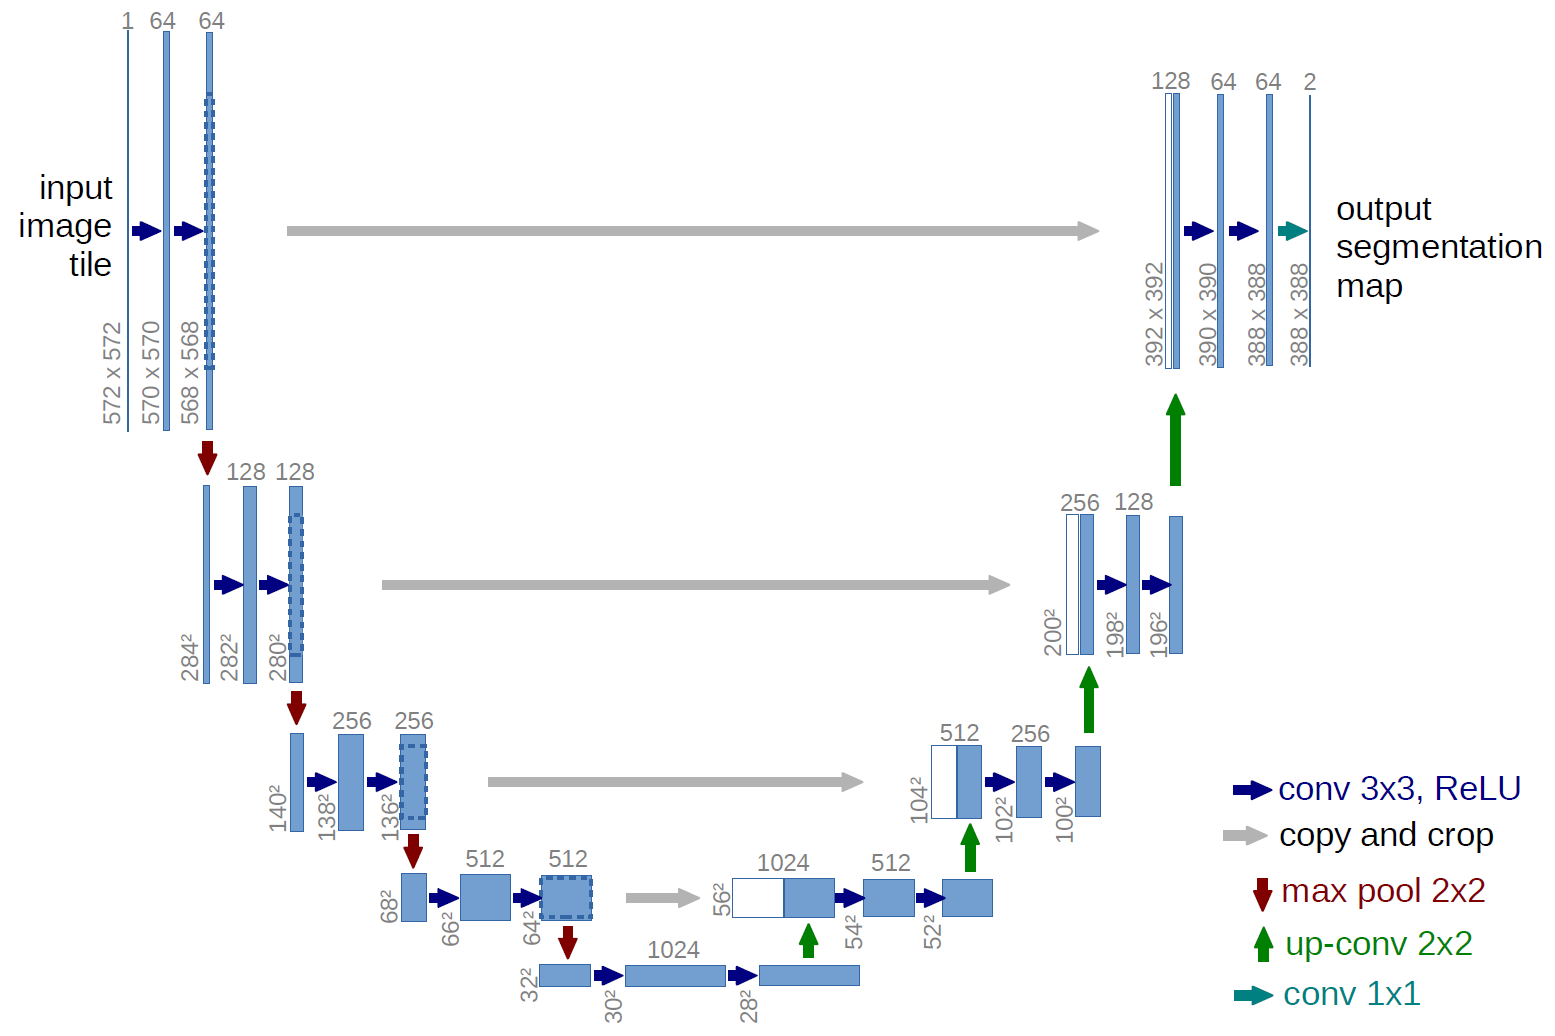
Сначала понижаем размерность в первой дуге, во второй увеличиваем.

Используется для борьбы с аномалиями, сегментации изображений.

<center><h2>CNN архитектура и классификация изображений

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=2, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(in_channels=4, out_channels=8, kernel_size=3)
        self.pool2 = nn.MaxPool2d(kernel_size=3)
        self.conv3 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2)
        self.linear1 = nn.Linear(in_features=64, out_features=32)
        self.linear2 = nn.Linear(in_features=32, out_features=10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()
        # Для преобразование выходов со сверточных слоев в единый массив для линейных слоев
        self.layers = [self.conv1, self.activation, self.pool1,
                       self.conv2, self.activation, self.pool2,
                       self.conv3, self.activation, self.pool3,
                       self.flatten, self.linear1, self.activation,
                       self.linear2]
        
    def forward(self, x):
        self.feature_maps = []
        for layer in self.layers:
            x = layer(x)
            if isinstance(layer, nn.Conv2d):
                self.feature_maps.append(x.detach())
                # detach для отделения изображения графа без градиентов (копия изначального элемента)
        return x

Поменяем pool и activation местами

In [70]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=2, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(in_channels=4, out_channels=8, kernel_size=3)
        self.pool2 = nn.MaxPool2d(kernel_size=3)
        self.conv3 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2)
        self.linear1 = nn.Linear(in_features=64, out_features=32)
        self.linear2 = nn.Linear(in_features=32, out_features=10)
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()
        # Для преобразование выходов со сверточных слоев в единый массив для линейных слоев
        self.layers = [self.conv1, self.pool1, self.activation,
                       self.conv2, self.activation, self.pool2,
                       self.conv3, self.pool3, self.activation,
                       self.flatten, self.linear1, self.activation,
                       self.linear2]
        
    def forward(self, x):
        self.feature_maps = []
        for layer in self.layers:
            x = layer(x)
            if isinstance(layer, nn.Conv2d):
                self.feature_maps.append(x.detach())
                # detach для отделения изображения графа без градиентов (копия изначального элемента)
        return x

In [43]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [71]:
model = CNN()
model.to(device)

CNN(
  (conv1): Conv2d(1, 4, kernel_size=(2, 2), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (linear1): Linear(in_features=64, out_features=32, bias=True)
  (linear2): Linear(in_features=32, out_features=10, bias=True)
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
)

In [72]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [64]:
print(sum(p.numel() for p in model.parameters()))

3894


In [73]:
import numpy as np


EPOCHS = 10
for epoch in range(EPOCHS):
    model.train()
    train_loss = []
    valid_loss = []
    print(f'Starting epoch {epoch + 1}')
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())
    
    model.eval()
    with torch.inference_mode():
        total_correct = 0
        total_samples = len(valid_loader.dataset)
        for data, targets in valid_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            valid_loss.append(loss.item())
            classes = torch.argmax(outputs, dim=-1)
            correct = (classes == targets).sum().item()
            total_correct += correct
    print(f'epoch {epoch + 1} trains_loss: {np.mean(train_loss)} valid_loss: {np.mean(valid_loss)} accuracy: {100 * total_correct / total_samples}')


Starting epoch 1
epoch 1 trains_loss: 1.9791119539260864 valid_loss: 1.1312816544532776 accuracy: 66.53
Starting epoch 2
epoch 2 trains_loss: 0.8263575947125753 valid_loss: 0.6252372890353203 accuracy: 81.13
Starting epoch 3
epoch 3 trains_loss: 0.5274800947348277 valid_loss: 0.4308936398148537 accuracy: 87.01
Starting epoch 4
epoch 4 trains_loss: 0.3903777562379837 valid_loss: 0.3333348004102707 accuracy: 90.3
Starting epoch 5
epoch 5 trains_loss: 0.32031626311937966 valid_loss: 0.28842573187947274 accuracy: 91.07
Starting epoch 6
epoch 6 trains_loss: 0.2798501120507717 valid_loss: 0.2490322838127613 accuracy: 92.57
Starting epoch 7
epoch 7 trains_loss: 0.2524617379794518 valid_loss: 0.22489093854948877 accuracy: 93.32
Starting epoch 8
epoch 8 trains_loss: 0.23251698527038098 valid_loss: 0.21166397037282586 accuracy: 93.52
Starting epoch 9
epoch 9 trains_loss: 0.21684054206510384 valid_loss: 0.1938627630647272 accuracy: 94.03
Starting epoch 10
epoch 10 trains_loss: 0.204437559902668 v

In [49]:
import matplotlib.pyplot as plt


def vizualize_feature_maps(feature_maps):
    num_layers = len(feature_maps)
    for layer_idx, feature_map in enumerate(feature_maps):
        num_filters = feature_map.shape[1]
        plt.figure(figsize=(15, 8))
        print(f'Layer {layer_idx + 1}')
        for i in range(min(num_filters, 16)):
            plt.subplot(4, 4, i + 1)
            plt.imshow(feature_map[0, i].cpu().numpy(), cmap='gray')
            plt.axis('off')
        plt.show()

Layer 1


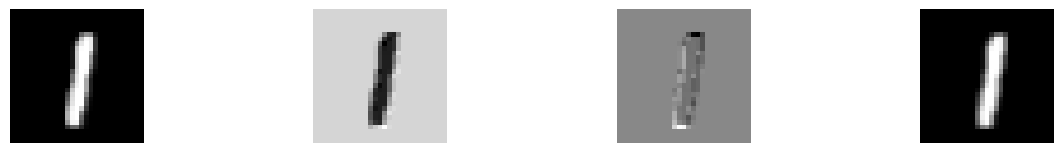

Layer 2


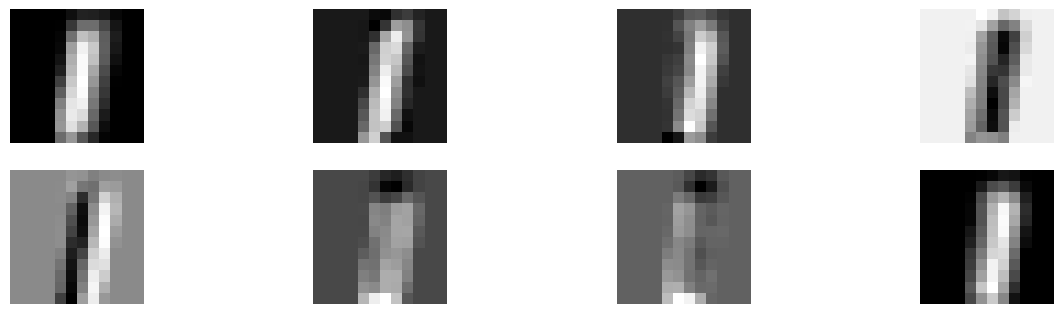

Layer 3


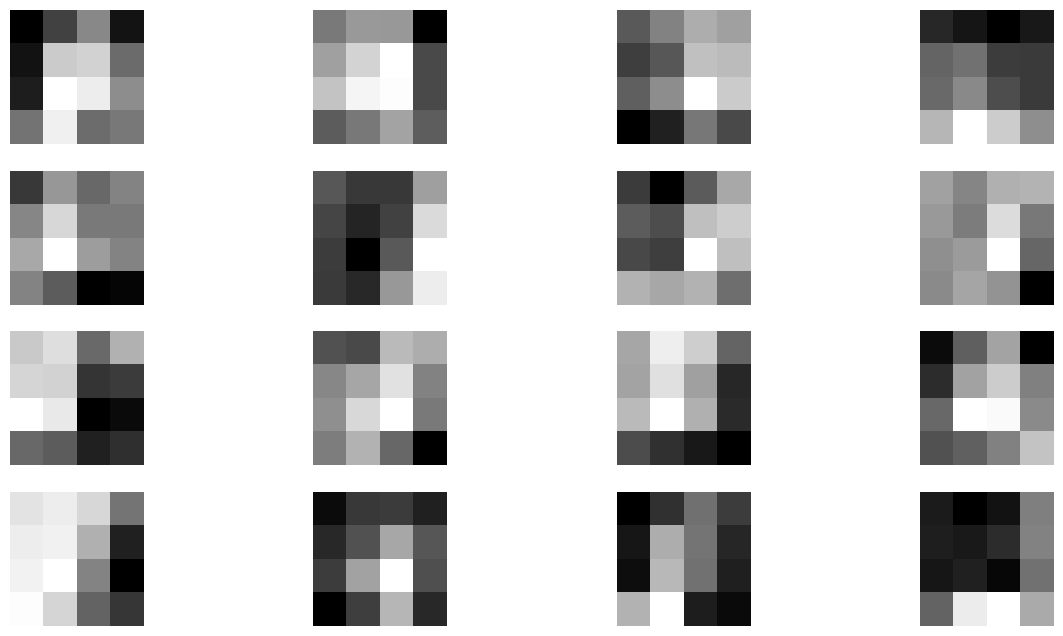

In [74]:
vizualize_feature_maps(model.feature_maps)

In [68]:
def inference(model, valid_loader):
    model.eval()
    dataiter = iter(valid_loader)
    data, targets = next(dataiter)
    data, targets = data.to(device), targets.to(device)
    outputs = model(data)
    outputs = torch.argmax(outputs, dim=1)
    return outputs, targets

In [69]:
outputs, targets = inference(model, valid_loader)
print(outputs)
print()
print(targets)

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 7, 0, 6, 9, 0, 1, 5], device='cuda:0')

tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5], device='cuda:0')


<center><h2>Практическое задание</h2></center>


1. Реализовать кастомный класс свертки, используя только Numpy

2. Обучить CNN в PyTorch с использовании разработанного вами класса